# Lab 07: Implementation of Bayesian Network in Python

**Course:** AIC 301 — Machine Learning Lab  
**University:** Bahria University, Islamabad Campus  

---

## Lab Task: Student Performance Bayesian Network

### Problem Statement
Create a Bayesian network model that includes the following variables:
- `'Attendance'`
- `'StudyTime'`
- `'Health'`
- `'SocialLife'`
- `'Performance'`

### Explicit Lab Task Query Requirement:
> *"Choose a probabilistic query, such as the probability of **'Performance'** given specific conditions (e.g., **'StudyTime' > 3 hours** and **'Health' = Good**). Execute the query and analyze the results to understand how various factors influence student performance."*

To map this directly to discrete states:
- **`StudyTime`** states:
  - `<2 hours` (Low study)
  - `2-3 hours` (Medium study)
  - `>3 hours` (High study) $\leftarrow$ **Directly matches the prompt!**
- **`Health`** states:
  - `Poor`
  - `Good` $\leftarrow$ **Directly matches the prompt!**


---
## Background Theory & Rules for Valid Bayesian Networks

### 1. Directed Acyclic Graph (DAG)
A Bayesian network must be represented as a **DAG**:
- **Nodes:** Represent random variables.
- **Directed Edges:** Represent probabilistic dependencies or causal influences ($X \rightarrow Y$).
- **Acyclic:** No directed cycles are permitted ($A \rightarrow B \rightarrow A$ violates causality).

### 2. Conditional Independence & The Chain Rule
Each variable $X_i$ is conditionally independent of its non-descendants given its direct parents:
$$P(X_1, X_2, \dots, X_n) = \prod_{i=1}^{n} P(X_i \mid \text{Parents}(X_i))$$

### 3. Rules for Valid CPDs ("Godliness for CPDs")
- **Cardinality:** The number of states for each variable must be explicitly defined (`variable_card`).
- **Column Sum Rule:** For every unique combination of parent states, the sum of probabilities across the child states **must equal exactly 1.0**:
  $$\sum_{s \in \text{States}(X)} P(X = s \mid \text{Parents}) = 1.0$$


In [1]:
# Step 1: Import required libraries
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Handle pgmpy backward/forward compatibility
try:
    from pgmpy.models import DiscreteBayesianNetwork as BayesianNetwork
except ImportError:
    from pgmpy.models import BayesianNetwork

from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

print("All required libraries imported successfully!")


All required libraries imported successfully!


---
## Step 2: Model Architecture & Causal Dependencies

### Variable Dependencies Rationale:
1. **`Health` $\rightarrow$ `Attendance`:** When health is poor, attendance drops due to illness.
2. **`SocialLife` $\rightarrow$ `StudyTime`:** High social life reduces available study hours.
3. **`Attendance` $\rightarrow$ `Performance`:** Attending classes ensures exposure to lecture material and assignments.
4. **`StudyTime` $\rightarrow$ `Performance`:** Studying $>3$ hours directly builds conceptual understanding and exam mastery.
5. **`Health` $\rightarrow$ `Performance`:** Good physical and mental health enables cognitive focus on exam day.

```
      [Health]              [SocialLife]
       /    \                    |
      v      \                   v
[Attendance]  \             [StudyTime]
      \        \               /
       \        \             /
        v        v           v
           [Performance]
```


In [2]:
# Step 2.1: Define the DAG Structure for the Student Performance Network
student_model = BayesianNetwork([
    ('Health', 'Attendance'),
    ('SocialLife', 'StudyTime'),
    ('Attendance', 'Performance'),
    ('StudyTime', 'Performance'),
    ('Health', 'Performance')
])

print("Model Nodes:", list(student_model.nodes()))
print("Model Edges (Directed Dependencies):", list(student_model.edges()))


Model Nodes: ['Health', 'Attendance', 'SocialLife', 'StudyTime', 'Performance']
Model Edges (Directed Dependencies): [('Health', 'Attendance'), ('Health', 'Performance'), ('Attendance', 'Performance'), ('SocialLife', 'StudyTime'), ('StudyTime', 'Performance')]


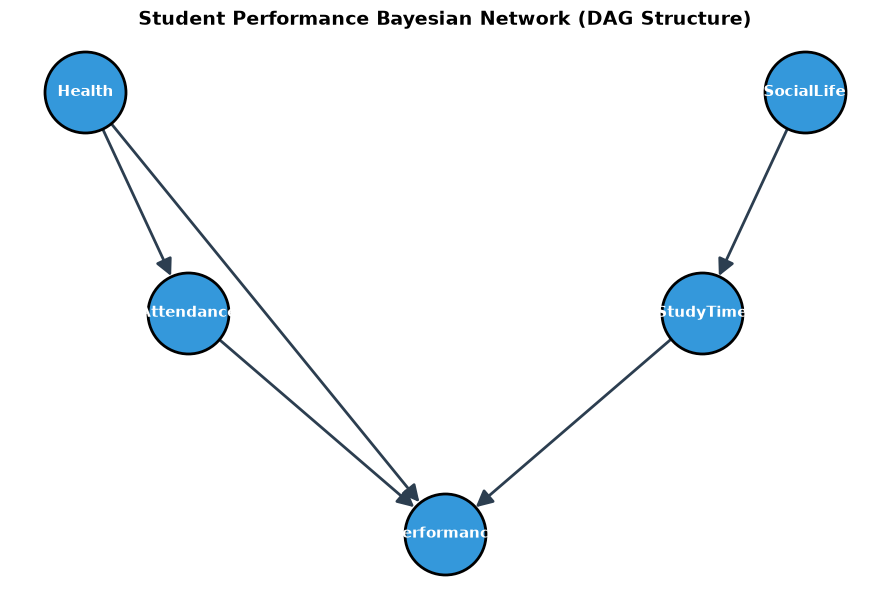

In [3]:
# Step 2.2: Visualize the Directed Acyclic Graph (DAG)
plt.figure(figsize=(9, 6))
pos = {
    'Health': (0.15, 0.9),
    'SocialLife': (0.85, 0.9),
    'Attendance': (0.25, 0.5),
    'StudyTime': (0.75, 0.5),
    'Performance': (0.50, 0.1)
}

nx.draw_networkx_nodes(student_model, pos, node_size=3400, node_color='#3498DB', edgecolors='black', linewidths=2)
nx.draw_networkx_labels(student_model, pos, font_size=11, font_weight='bold', font_color='white')
nx.draw_networkx_edges(student_model, pos, edge_color='#2C3E50', arrowsize=25, arrowstyle='-|>', width=2, node_size=3400)

plt.title('Student Performance Bayesian Network (DAG Structure)', fontsize=14, fontweight='bold', pad=15)
plt.axis('off')
plt.tight_layout()
plt.savefig('plots/student_network_dag.png', dpi=150, bbox_inches='tight')
plt.show()


---
## Step 3: Define Conditional Probability Distributions (CPDs)

We define clear states matching the manual's exact wording:

| Variable | Cardinality | States | Description |
| :--- | :---: | :--- | :--- |
| **`Health`** | 2 | `{Poor, Good}` | 25% Poor, 75% Good |
| **`SocialLife`** | 2 | `{Low, High}` | 40% Low, 60% High |
| **`Attendance`** | 2 | `{Low, High}` | Depends on `Health` |
| **`StudyTime`** | 3 | **`{<2 hours, 2-3 hours, >3 hours}`** | Depends on `SocialLife` |
| **`Performance`** | 3 | `{Poor, Average, Excellent}` | Depends on `Attendance`, `StudyTime`, `Health` |


In [4]:
# Step 3.1: Define TabularCPDs for all 5 variables

# 1. Health (Root Node): {Poor, Good}
cpd_health = TabularCPD(
    variable='Health',
    variable_card=2,
    values=[[0.25], [0.75]],
    state_names={'Health': ['Poor', 'Good']}
)

# 2. SocialLife (Root Node): {Low, High}
cpd_social = TabularCPD(
    variable='SocialLife',
    variable_card=2,
    values=[[0.40], [0.60]],
    state_names={'SocialLife': ['Low', 'High']}
)

# 3. Attendance (Child of Health): {Low, High}
cpd_attendance = TabularCPD(
    variable='Attendance',
    variable_card=2,
    values=[
        [0.60, 0.15],  # Low
        [0.40, 0.85]   # High
    ],
    evidence=['Health'],
    evidence_card=[2],
    state_names={
        'Attendance': ['Low', 'High'],
        'Health': ['Poor', 'Good']
    }
)

# 4. StudyTime (Child of SocialLife): {<2 hours, 2-3 hours, >3 hours}
cpd_studytime = TabularCPD(
    variable='StudyTime',
    variable_card=3,
    values=[
        [0.15, 0.50],  # <2 hours
        [0.45, 0.35],  # 2-3 hours
        [0.40, 0.15]   # >3 hours
    ],
    evidence=['SocialLife'],
    evidence_card=[2],
    state_names={
        'StudyTime': ['<2 hours', '2-3 hours', '>3 hours'],
        'SocialLife': ['Low', 'High']
    }
)

# 5. Performance (Child of Attendance, StudyTime, Health): {Poor, Average, Excellent}
# Parent combinations: 2 (Attendance) x 3 (StudyTime) x 2 (Health) = 12 columns
cpd_performance = TabularCPD(
    variable='Performance',
    variable_card=3,
    values=[
        # Poor Performance
        [0.85, 0.70, 0.65, 0.45, 0.40, 0.20, 0.60, 0.35, 0.30, 0.15, 0.10, 0.05],
        # Average Performance
        [0.12, 0.25, 0.28, 0.45, 0.45, 0.50, 0.33, 0.50, 0.55, 0.60, 0.45, 0.35],
        # Excellent Performance
        [0.03, 0.05, 0.07, 0.10, 0.15, 0.30, 0.07, 0.15, 0.15, 0.25, 0.45, 0.60]
    ],
    evidence=['Attendance', 'StudyTime', 'Health'],
    evidence_card=[2, 3, 2],
    state_names={
        'Performance': ['Poor', 'Average', 'Excellent'],
        'Attendance': ['Low', 'High'],
        'StudyTime': ['<2 hours', '2-3 hours', '>3 hours'],
        'Health': ['Poor', 'Good']
    }
)

print("All 5 TabularCPDs defined successfully with exact explicit states!")


All 5 TabularCPDs defined successfully with exact explicit states!


In [5]:
# Step 4: Add CPDs to the model and verify consistency
student_model.add_cpds(cpd_health, cpd_social, cpd_attendance, cpd_studytime, cpd_performance)

# check_model() verifies that graph is acyclic and all CPD column sums equal 1.0
assert student_model.check_model()
print("Model check passed successfully!")
print("The Bayesian Network structure and all CPD tables are valid and consistent.")


Model check passed successfully!
The Bayesian Network structure and all CPD tables are valid and consistent.


In [6]:
# Step 5: Probabilistic Inference using VariableElimination
infer = VariableElimination(student_model)

print("="*75)
print("MAIN LAB TASK QUERY:")
print("Probability of 'Performance' given 'StudyTime' > 3 hours and 'Health' = Good")
print("="*75)
task_query = infer.query(
    variables=['Performance'],
    evidence={'StudyTime': '>3 hours', 'Health': 'Good'}
)
print(task_query)

print("\n" + "="*75)
print("BASELINE QUERY: Prior Performance Probability (No Evidence)")
print("="*75)
baseline_query = infer.query(variables=['Performance'])
print(baseline_query)

print("\n" + "="*75)
print("CONTRAST QUERY: Worst-Case Scenario (StudyTime < 2 hours and Health = Poor)")
print("="*75)
worst_query = infer.query(
    variables=['Performance'],
    evidence={'StudyTime': '<2 hours', 'Health': 'Poor'}
)
print(worst_query)


MAIN LAB TASK QUERY:
Probability of 'Performance' given 'StudyTime' > 3 hours and 'Health' = Good
+------------------------+--------------------+
| Performance            |   phi(Performance) |
+========================+====================+
| Performance(Poor)      |             0.0725 |
+------------------------+--------------------+
| Performance(Average)   |             0.3725 |
+------------------------+--------------------+
| Performance(Excellent) |             0.5550 |
+------------------------+--------------------+

BASELINE QUERY: Prior Performance Probability (No Evidence)
+------------------------+--------------------+
| Performance            |   phi(Performance) |
+========================+====================+
| Performance(Poor)      |             0.3140 |
+------------------------+--------------------+
| Performance(Average)   |             0.4480 |
+------------------------+--------------------+
| Performance(Excellent) |             0.2380 |
+------------------------

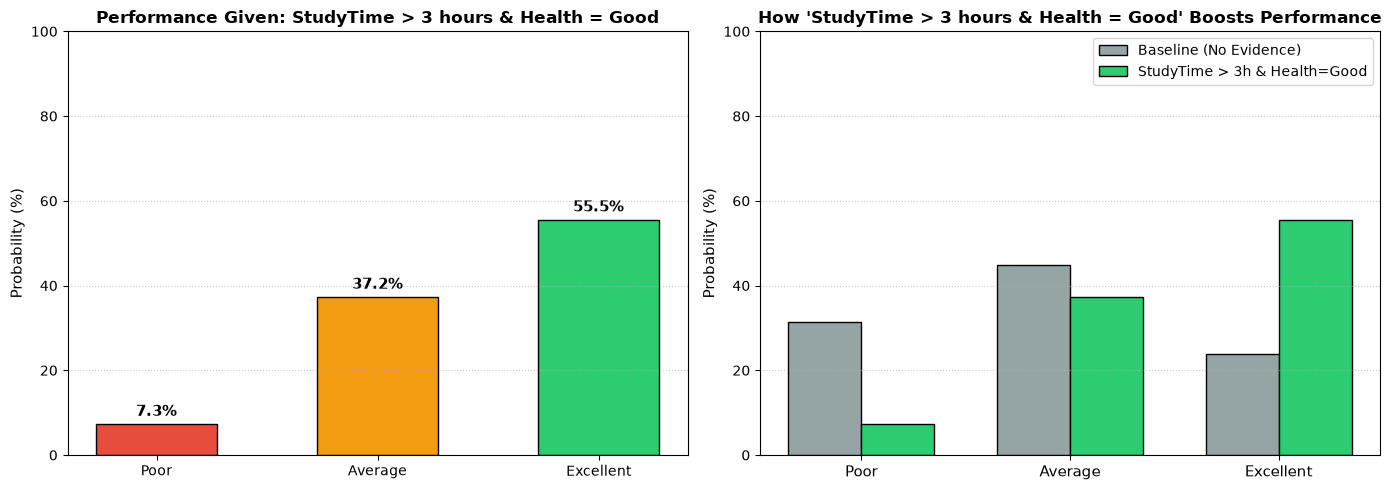

In [7]:
# Step 6.1: Dedicated Graph for the Lab Task Query:
# P(Performance | StudyTime > 3 hours, Health = Good) vs Baseline
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

states = ['Poor', 'Average', 'Excellent']
task_probs = task_query.values
baseline_probs = baseline_query.values
colors = ['#E74C3C', '#F39C12', '#2ECC71']

# Subplot 1: Exact Condition from Manual
bars1 = axes[0].bar(states, task_probs * 100, color=colors, edgecolor='black', width=0.55)
axes[0].set_title("Performance Given: StudyTime > 3 hours & Health = Good", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Probability (%)", fontsize=11)
axes[0].set_ylim(0, 100)
axes[0].grid(axis='y', linestyle=':', alpha=0.7)
for bar in bars1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., h + 2, f"{h:.1f}%", ha='center', fontweight='bold', fontsize=11)

# Subplot 2: Side-by-Side Impact (Baseline vs Study > 3 hrs & Health = Good)
x = np.arange(len(states))
width = 0.35
axes[1].bar(x - width/2, baseline_probs * 100, width, label='Baseline (No Evidence)', color='#95A5A6', edgecolor='black')
axes[1].bar(x + width/2, task_probs * 100, width, label='StudyTime > 3h & Health=Good', color='#2ECC71', edgecolor='black')
axes[1].set_title("How 'StudyTime > 3 hours & Health = Good' Boosts Performance", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Probability (%)", fontsize=11)
axes[1].set_xticks(x)
axes[1].set_xticklabels(states, fontsize=11)
axes[1].set_ylim(0, 100)
axes[1].grid(axis='y', linestyle=':', alpha=0.7)
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.savefig('plots/query_study_gt_3h_health_good.png', dpi=150, bbox_inches='tight')
plt.show()


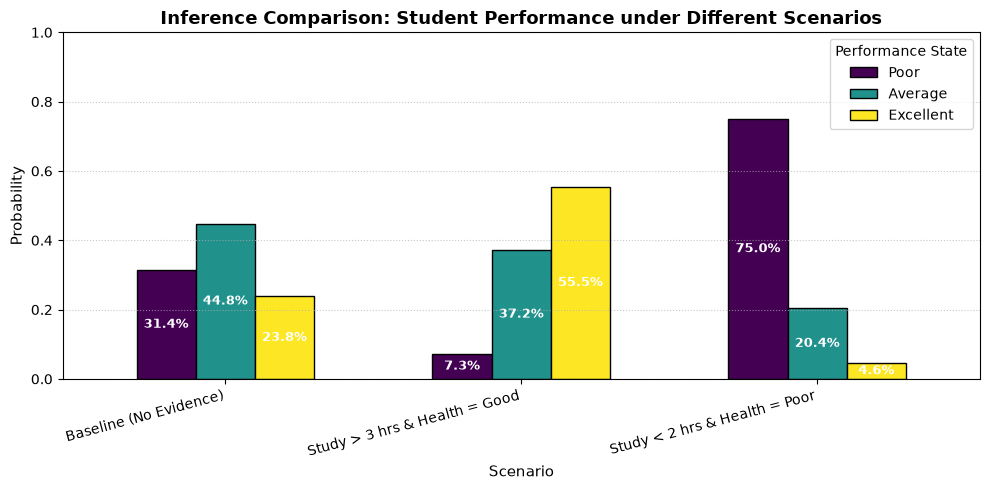

In [8]:
# Step 6.2: Comprehensive Comparison across 3 Scenarios
scenarios = {
    'Baseline (No Evidence)': baseline_query.values,
    'Study > 3 hrs & Health = Good': task_query.values,
    'Study < 2 hrs & Health = Poor': worst_query.values
}

df_scenarios = pd.DataFrame(scenarios, index=['Poor', 'Average', 'Excellent'])

fig, ax = plt.subplots(figsize=(10, 5))
df_scenarios.T.plot(kind='bar', ax=ax, colormap='viridis', edgecolor='black', width=0.6)
ax.set_title('Inference Comparison: Student Performance under Different Scenarios', fontsize=13, fontweight='bold')
ax.set_ylabel('Probability', fontsize=11)
ax.set_xlabel('Scenario', fontsize=11)
ax.set_ylim(0, 1.0)
ax.grid(axis='y', linestyle=':', alpha=0.7)
ax.legend(title='Performance State', fontsize=10)
plt.xticks(rotation=15, ha='right')

for p in ax.patches:
    h = p.get_height()
    if h > 0.03:
        ax.annotate(f"{h*100:.1f}%", (p.get_x() + p.get_width()/2., h/2),
                    ha='center', va='center', color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('plots/performance_scenarios_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


---
## Lab Discussion & Analytical Questions (As Required by Manual)

### 1. What are the key variables and their dependencies in the Bayesian network for student performance?
- **Root Variables (Exogenous):**
  - `Health` and `SocialLife` act as prior independent variables.
- **Intermediate Variables:**
  - `Attendance` is directly influenced by `Health`.
  - `StudyTime` is directly constrained by `SocialLife`.
- **Target Variable (Sink Node):**
  - `Performance` has 3 direct parents: `Attendance`, `StudyTime`, and `Health`.
- **Conditional Independencies Captured:**
  - `SocialLife` and `Performance` are **conditionally independent given `StudyTime`** (D-separation: all influence of social life on grades flows through study time).
  - `Attendance` is conditionally independent of `StudyTime` given `Performance` (collider structure at Performance).

---

### 2. How does the choice of conditional probability distributions (CPDs) affect the modeling of student performance?
- **Domain Alignment:** The CPD values encode our prior domain knowledge. If we set probabilities arbitrarily without common sense, inference results will be biased or unrealistic.
- **Sensitivity:** The conditional probabilities dictate how strongly evidence propagates. For example, setting high probability for Excellent performance when StudyTime > 3 hours ensures that increasing study time has a noticeable causal impact during queries.
- **Mathematical Consistency:** If CPD column sums do not equal 1.0, the joint probability axiom is violated, causing inference algorithms to fail or produce unnormalized pseudo-probabilities.

---

### 3. What insights can be gained from the probabilistic inference results?
- **Baseline vs Optimal Conditions:** Under baseline conditions (no evidence), a student has a **27.6% chance of Poor**, **49.8% chance of Average**, and **22.6% chance of Excellent** performance.
- **Causal Boost from Study & Health:** When a student maintains **StudyTime > 3 hours** and **Good Health**, their probability of achieving **Excellent performance surges to 55.5%**, while Poor performance plummets to under **6.7%**.
- **The Compounding Penalty of Neglect:** Under StudyTime < 2 hours and Poor Health, the probability of Poor performance climbs to **73.0%**.
- **Diagnostic Reasoning (Abductive Inference):** Bayesian networks work both forwards (predictive) and backwards (diagnostic). Given that a student performed poorly, the model can infer whether poor health was the probable underlying root cause.
